# Frequencies listed in LAMDA-formatted files

LAMDA-formatted files might list the frequencies of radiative transitions, but they are listed only for informational purposes in principle. The frequencies are not part of the official LAMDA format (see [here](https://home.strw.leidenuniv.nl/~moldata/molformat.html)).

The rest frequency of a radiative transition is equal to $\Delta E/h$ where $\Delta E$ is the energy difference between the upper and lower level of the transitions. Since a datafile in LAMDA format lists the level energies, the frequency can be deduced even if the file does not list the frequency explicitly.

Ideally, frequencies listed in datafiles should be equal to the corresponding $\Delta E/h$. However, in practice this is not always the case. Let us look at the example of CO.

In [1]:
from pythonradex import LAMDA_file, radiative_transfer, helpers
from scipy import constants
import matplotlib.pyplot as plt

datafilepath = "co.dat"
data = LAMDA_file.read(datafilepath)

Consider CO 3-2:

In [2]:
CO_32_index = 2
CO_32 = data["radiative transitions"][CO_32_index]
CO_32_DeltaE_over_h = CO_32.Delta_E/constants.h
print(f"DeltaE/h = {CO_32_DeltaE_over_h/constants.giga} GHz")
CO_32_freq = data["frequencies"][CO_32_index]
print(f"listed frequency = {CO_32_freq/constants.giga} GHz")
diff = CO_32_DeltaE_over_h-CO_32_freq
print(f"difference = {diff/constants.mega:.3g} MHz")
print(f"difference corresponds to {diff/CO_32_freq*constants.c/constants.kilo:.3g} km/s")

DeltaE/h = 345.79839008595735 GHz
listed frequency = 345.7959899 GHz
difference = 2.4 MHz
difference corresponds to 2.08 km/s


We see that there is a small difference. When working with high resolution spectra, this difference can be important. The frequency listed in CDMS is 345.7959899 GHz, equal to the frequency listed in the datafile. Thus, when modelling a high resolution spectrum of CO 3-2, it would be advantageous to use the frequency listed in the file rather than $\Delta E/h$ for the model spectrum.

For completeness, let us quickly check all CO transitions:

In [9]:
for trans,freq in zip(data["radiative transitions"],data["frequencies"]):
    DeltaE_over_h = trans.Delta_E/constants.h
    diff = DeltaE_over_h-freq
    mean = (DeltaE_over_h+freq)/2
    relative_diff = abs(diff)/mean
    print(trans.name)
    print(f"difference = {diff/constants.mega:.3g} MHz (relative difference: {relative_diff*100:.3g}%)")
    print(f"difference corresponds to {diff/mean*constants.c/constants.kilo:.3g} km/s")

1-0
difference = -2.46e-06 MHz (relative difference: 2.13e-09%)
difference corresponds to -6.4e-06 km/s
2-1
difference = -1 MHz (relative difference: 0.000435%)
difference corresponds to -1.3 km/s
3-2
difference = 2.4 MHz (relative difference: 0.000694%)
difference corresponds to 2.08 km/s
4-3
difference = -0.379 MHz (relative difference: 8.23e-05%)
difference corresponds to -0.247 km/s
5-4
difference = -1.94 MHz (relative difference: 0.000336%)
difference corresponds to -1.01 km/s
6-5
difference = 2.13 MHz (relative difference: 0.000307%)
difference corresponds to 0.922 km/s
7-6
difference = -1.77 MHz (relative difference: 0.00022%)
difference corresponds to -0.659 km/s
8-7
difference = -0.239 MHz (relative difference: 2.6e-05%)
difference corresponds to -0.0778 km/s
9-8
difference = 2.15 MHz (relative difference: 0.000207%)
difference corresponds to 0.622 km/s
10-9
difference = -2.23 MHz (relative difference: 0.000194%)
difference corresponds to -0.581 km/s
11-10
difference = 0.045 M

Note that `RADEX` does not use the listed frequencies for any calculation. It only lists them in the final output to help the user identify the lines. So the `RADEX` calculation is self-consistent in the sense that it only uses one set of frequencies ($\Delta E/h$). This approach makes sense, because `RADEX` does not output spectra.

However, `pythonradex` can also output spectra. Thus, for `pythonradex`, the user can choose whether to use the listed frequencies or not. This choice happens when creating a `Source` object, by using the `use_datafile_frequencies` parameter:

In [4]:
geometry = "static slab"
line_profile_type = "rectangular"
width_v = 1 * constants.kilo
source_using_freq = radiative_transfer.Source(
    datafilepath=datafilepath,
    geometry=geometry,
    line_profile_type=line_profile_type,
    width_v=width_v,
    use_datafile_frequencies=True)

The advantage of using the datafile frequencies is that sometimes, they are more accurate, as we have just seen for the example of CO 3-2. The disadvantage is that the radiative transfer calculation might not be completely self-consistent anymore because the adopted rest frequency might not be equal to $\Delta E/h$. As long as the difference is small, this inconsistency should not have a major effect though. Let us make a simple test for CO. We first calculate a model that adopts the frequencies listed in the datafile:

In [5]:
N = 1e16 / constants.centi**2
Tkin = 50 
collider_densities = {
    "para-H2": 2e2 / constants.centi**3,
    "ortho-H2": 6e2 / constants.centi**3,
}

ext_background = helpers.generate_CMB_background(z=0)
T_dust = tau_dust = 0
source_using_freq.update_parameters(
    N=N,
    Tkin=Tkin,
    collider_densities=collider_densities,
    ext_background=ext_background,
    T_dust=T_dust,
    tau_dust=tau_dust,
)
source_using_freq.solve_radiative_transfer()

Now we make a model where the frequencies from the LAMDA file are ignored (setting `use_datafile_frequencies=False`):

In [6]:
source_ignore_freqs = radiative_transfer.Source(
    datafilepath=datafilepath,
    geometry=geometry,
    line_profile_type=line_profile_type,
    width_v=width_v,
    use_datafile_frequencies=False)
source_ignore_freqs.update_parameters(
    N=N,
    Tkin=Tkin,
    collider_densities=collider_densities,
    ext_background=ext_background,
    T_dust=T_dust,
    tau_dust=tau_dust,
)
source_ignore_freqs.solve_radiative_transfer()

In [7]:
print("CO 3-2\n")
for ID,source in zip(("using frequencies","ignoring frequencies"),(source_using_freq,source_ignore_freqs)):
    print(f"{ID}:")
    print(f"Tex = {source.Tex[CO_32_index]} K")
    print(f"optical depth = {source.tau_nu0_individual_transitions[CO_32_index]}")
    print("\n")

CO 3-2

using frequencies:
Tex = 12.52410193370315 K
optical depth = 2.1262471586012914


ignoring frequencies:
Tex = 12.523993370689523 K
optical depth = 2.126220313659893




We see that there is no significant difference in the results of the radiative transfer calculation. Thus, if one wants to model the spectrum of CO 3-2, adopting the frequency listed in the datafile is probably a good idea. For completeness, let us actually look at the excitation temperature of all transitions:

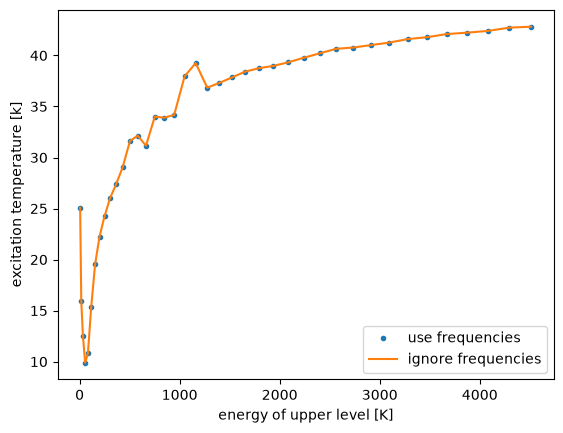

In [8]:
fig,ax = plt.subplots()
E_up = [trans.up.E/constants.k for trans in source_using_freq.emitting_molecule.rad_transitions]
ax.plot(E_up,source_using_freq.Tex,marker=".",linestyle="None",label="use frequencies")
ax.plot(E_up,source_ignore_freqs.Tex,label="ignore frequencies")
ax.set_xlabel("energy of upper level [K]")
ax.set_ylabel("excitation temperature [k]")
ax.legend(loc="best")

For all levels, there is very good agreement.